# India AQI ML Platform — Research Notebook 01
## 17 Years of Delhi Air Quality

**Author:** Anandhu Suresh
**Dataset:** `data/processed/historical_ml.csv` — 2009 → 2026, ~95 CPCB monitoring stations, all in Delhi
**Scope:** Exploratory Data Analysis. No modelling happens here — this notebook produces the *evidence* that will justify every modelling decision in Notebooks 02–04.

### Why this notebook is different from a textbook EDA

Most EDA notebooks answer questions the *data* asked. This notebook answers questions that **policymakers, epidemiologists, and climate scientists** actually ask:

1. Is temperature genuinely driving the winter PM₂.₅ surge, or is it a seasonal proxy?
2. Why does ozone *rise* when particulates *fall*? (The counter-intuitive "Ozone Paradox.")
3. Does rain clean the air, or just move pollution around?
4. Is PM₂.₅ chemically the same everywhere, or does the source mix differ by season?
5. How much of NO₂ is traffic? (The weekend is a natural experiment.)
6. How long does the Diwali explosion last before the air recovers?
7. What did the 2020 COVID lockdown *actually* prove about cars?
8. Which stations need targeted intervention — and on which pollutant?

Each answer produces a chart saved to `assets/eda_qN_*.png`, a statistical test, and a 3-sentence interpretation of the **"So What?"**. The final cell distils everything into 4 modelling implications.

> **Reproducibility.** Every chart is deterministic: fixed seeds, no random sampling, all data loads from `historical_ml.csv`, all feature engineering delegates to `src/processing/feature_eng.create_features()` so this notebook and the ML pipeline share a single source of truth.

In [ ]:
# =============================================================================
# Cell 2 — Environment setup, data load, shared feature engineering
# =============================================================================

# --- Path bootstrap (works from both `notebooks/` and project root) ---------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# --- Standard library -------------------------------------------------------
import warnings
warnings.filterwarnings("ignore")

# --- Third-party ------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- Project ----------------------------------------------------------------
from src.processing.feature_eng import create_features
from src.processing.cleaner_live import compute_sub_index

# --- Global style: one consistent theme across every chart -------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi":        110,
    "savefig.dpi":       160,
    "axes.titlesize":    14,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "legend.frameon":    True,
    "legend.framealpha": 0.92,
})

ASSETS = PROJECT_ROOT / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

# --- Shared colour palette (referenced by every chart) ----------------------
C = {
    "PM2.5":   "#d62728",
    "PM10":    "#ff7f0e",
    "NO2":     "#1f77b4",
    "OZONE":   "#2ca02c",
    "AT":      "#6a3d9a",
    "Rain":    "#17becf",
    "weekday": "#4c72b0",
    "weekend": "#dd8452",
    "dry":     "#a6cee3",
    "rainy":   "#1f78b4",
    "Winter":        "#4c72b0",
    "Summer":        "#dd8452",
    "Monsoon":       "#55a868",
    "Post-Monsoon":  "#c44e52",
    "grey":    "#555555",
}

# --- Utility: save + show + close (avoids figure leakage across cells) ------
def save_and_show(fig, filename: str):
    out = ASSETS / filename
    fig.savefig(out, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"✓ saved → {out}")

# --- Load the cleaned historical panel --------------------------------------
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "historical_ml.csv"
df = pd.read_csv(DATA_PATH)

# Parse timestamp and drop unparseable rows
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], errors="coerce", utc=True)
n_raw = len(df)
df = df.dropna(subset=["timestamp_utc"]).reset_index(drop=True)
print(f"Loaded {n_raw:,} rows; dropped {n_raw - len(df):,} with unparseable timestamps.")

# Shared feature engineering (Is_Weekend, Season, PM25_PM10_Ratio)
df = create_features(df)

df['city'] = 'Delhi'
# Convert boolean to numpy bool for downstream sum/mean arithmetic
df["Is_Weekend"] = df["Is_Weekend"].astype("boolean").fillna(False).astype(bool)

print(f"Final shape: {df.shape[0]:,} rows × {df.shape[1]} columns")---
## 5 · Key Takeaways — Four Bullets That Drive Notebooks 02–04

Across all 8 questions, four structural facts stand out. These are the modelling
assumptions we will carry forward into the regression, classification, and
clustering notebooks — and defend in the final report.

### 1. Temperature and the boundary layer are the dominant seasonal drivers.

Q1 and Q2 together prove that **meteorology, not just emissions, sets the
seasonal baseline**. Winter PM₂.₅ spikes because the atmosphere concentrates
pollution (Pearson *r* = **−0.58** with temperature), not necessarily because
people burn more. Summer ozone spikes because sunlight cooks NOₓ and VOCs
(Ozone peaks in **May**, while PM₂.₅ peaks in **November**).

**Consequence:** `AT`, `RH`, `WS`, `Season`, and a `1/AT` transform belong in
every regression. Any model without meteorology is fitting a proxy.

### 2. Delhi has two pollution seasons, and they have different sources.

Q4 shows the PM₂.₅/PM₁₀ ratio shifts by **1.35×** between winter (**0.602**) and
summer (**0.444**). The regression slope for PM₂.₅ vs PM₁₀ is much steeper in
Winter (**0.479**) than in Summer (**0.276**). Winter air is fine-particle-
dominated (combustion); summer air is coarse-particle-dominated (dust).

**Consequence:** don't use PM₁₀ as a proxy for PM₂.₅; model them as separate
targets. `PM25_PM10_Ratio` and `Season` are essential features, not nice-to-haves.

### 3. Traffic is the dominant, policy-responsive NO₂ source.

Q5 and Q7 bracket the traffic-attributable fraction of NO₂ perfectly. Normal
weekends only cut NO₂ by **5.3%** (proving commercial traffic remains heavy), but
the 2020 lockdown cut it by **55.7%**.

**Consequence:** traffic controls work on the NO₂ axis. `Is_Weekend` and
`day_of_week` are essential features; the 2020 lockdown is a massive distribution
shift that must be flagged (`is_lockdown_2020`) or excluded from training.

### 4. One global Delhi model is the wrong shape.

Q6 proves Diwali is not just a 1-day event; it takes **13 days** for the air to
recover to baseline. Q8 shows the worst stations (Anand Vihar, Punjabi Bagh) are
actually **PM₁₀-dominated**, not PM₂.₅.

**Consequence:** build (a) a **global** model with `station_id` and
`days_from_diwali` features, and (b) a **station-clustered** set of specialist
models in Notebook 04.

---

### Hand-off contract to Notebook 02

Here are the engineered features that will form the starting matrix for
Notebook 02's regression arena. Nothing here is speculative — every column has
a statistical test and a "So What?" to defend its inclusion.

| Feature | Source | Justification |
|---|---|---|
| `AT`, `RH`, `WS` | raw | Q1, Q2 (Meteorology) |
| `Season`, `PM25_PM10_Ratio` | `create_features` | Q4 (Source Shift) |
| `Is_Weekend`, `day_of_week` | `create_features` + engineering | Q5 (Traffic) |
| `days_from_diwali` | engineering | Q6 (13-day recovery trap) |
| `Rain`, `Rain_lag_6h`, `Rain_lag_24h` | raw + engineering | Q3 (−66% Washout) |
| `station_id` (categorical) | raw | Q8 (Achilles Heel) |
| `is_lockdown_2020` | engineering | Q7 (Distribution shift) |

> **Note.** Raw pollutant levels will also be included as features. Missing
> values will be imputed inside a scikit-learn `Pipeline` in Notebook 02 to
> prevent data leakage.---
## 5 · Key Takeaways — Four Bullets That Drive Notebooks 02–04

Across all 8 questions, four structural facts stand out. These are the modelling
assumptions we will carry forward into the regression, classification, and
clustering notebooks — and defend in the final report.

### 1. Temperature and the boundary layer are the dominant seasonal drivers.

Q1 and Q2 together prove that **meteorology, not just emissions, sets the
seasonal baseline**. Winter PM₂.₅ spikes because the atmosphere concentrates
pollution (Pearson *r* = **−0.58** with temperature), not necessarily because
people burn more. Summer ozone spikes because sunlight cooks NOₓ and VOCs
(Ozone peaks in **May**, while PM₂.₅ peaks in **November**).

**Consequence:** `AT`, `RH`, `WS`, `Season`, and a `1/AT` transform belong in
every regression. Any model without meteorology is fitting a proxy.

### 2. Delhi has two pollution seasons, and they have different sources.

Q4 shows the PM₂.₅/PM₁₀ ratio shifts by **1.35×** between winter (**0.602**) and
summer (**0.444**). The regression slope for PM₂.₅ vs PM₁₀ is much steeper in
Winter (**0.479**) than in Summer (**0.276**). Winter air is fine-particle-
dominated (combustion); summer air is coarse-particle-dominated (dust).

**Consequence:** don't use PM₁₀ as a proxy for PM₂.₅; model them as separate
targets. `PM25_PM10_Ratio` and `Season` are essential features, not nice-to-haves.

### 3. Traffic is the dominant, policy-responsive NO₂ source.

Q5 and Q7 bracket the traffic-attributable fraction of NO₂ perfectly. Normal
weekends only cut NO₂ by **5.3%** (proving commercial traffic remains heavy), but
the 2020 lockdown cut it by **55.7%**.

**Consequence:** traffic controls work on the NO₂ axis. `Is_Weekend` and
`day_of_week` are essential features; the 2020 lockdown is a massive distribution
shift that must be flagged (`is_lockdown_2020`) or excluded from training.

### 4. One global Delhi model is the wrong shape.

Q6 proves Diwali is not just a 1-day event; it takes **13 days** for the air to
recover to baseline. Q8 shows the worst stations (Anand Vihar, Punjabi Bagh) are
actually **PM₁₀-dominated**, not PM₂.₅.

**Consequence:** build (a) a **global** model with `station_id` and
`days_from_diwali` features, and (b) a **station-clustered** set of specialist
models in Notebook 04.

---

### Hand-off contract to Notebook 02

Here are the engineered features that will form the starting matrix for
Notebook 02's regression arena. Nothing here is speculative — every column has
a statistical test and a "So What?" to defend its inclusion.

| Feature | Source | Justification |
|---|---|---|
| `AT`, `RH`, `WS` | raw | Q1, Q2 (Meteorology) |
| `Season`, `PM25_PM10_Ratio` | `create_features` | Q4 (Source Shift) |
| `Is_Weekend`, `day_of_week` | `create_features` + engineering | Q5 (Traffic) |
| `days_from_diwali` | engineering | Q6 (13-day recovery trap) |
| `Rain`, `Rain_lag_6h`, `Rain_lag_24h` | raw + engineering | Q3 (−66% Washout) |
| `station_id` (categorical) | raw | Q8 (Achilles Heel) |
| `is_lockdown_2020` | engineering | Q7 (Distribution shift) |

> **Note.** Raw pollutant levels will also be included as features. Missing
> values will be imputed inside a scikit-learn `Pipeline` in Notebook 02 to
> prevent data leakage.

Loaded 146,708 rows; dropped 0 with unparseable timestamps.
Final shape: 146,708 rows × 30 columns


### 1.1 — Data Audit

Before we trust any chart, we audit the raw panel: how many rows, what's missing,
and where the statistical mass actually lives. The three checks below are the
minimum bar for any dataset that will feed a production model.

**On missing values — a deliberate non-decision:** we do **not** globally impute
or drop. Each analysis in this notebook has a different missing-value contract
(Q1 needs `AT`; Q3 needs `Rain`; Q7 needs `NO2` in exactly two Aprils), so
missingness is handled **per-question** with an explicit `.dropna(subset=[...])`
that names exactly which columns the analysis depends on. Global imputation at
this stage would quietly change the pollution distribution — for example, mean-
imputing PM2.5 would flatten the very Diwali spikes we're trying to detect in Q6.
The **modelling** notebooks (02–04) are where imputation happens — inside a
`Pipeline`, after train/test split, to avoid leakage.

In [2]:
# =============================================================================
# Cell 4 — Data audit
# =============================================================================

print("=" * 74)
print("AUDIT · DataFrame info")
print("=" * 74)
df.info(verbose=False, show_counts=True)

print("\n" + "=" * 74)
print("AUDIT · Missing values (top 15, % of rows)")
print("=" * 74)
miss = (
    df.isna().mean().mul(100).round(2)
      .sort_values(ascending=False)
      .head(15)
)
print(miss.to_string())

print("\n" + "=" * 74)
print("AUDIT · Key coverage")
print("=" * 74)
cov = pd.Series({
    "Date range (UTC)":     f"{df.timestamp_utc.min().date()} → {df.timestamp_utc.max().date()}",
    "Unique stations":      df["station"].nunique(),
    "Unique cities":        df["city"].nunique() if "city" in df.columns else "N/A",
    "Unique states":        df["state"].nunique() if "state" in df.columns else "N/A",
    "Total rows":           f"{len(df):,}",
    "Rows with AQI":        f"{df['AQI'].notna().sum():,}  ({df['AQI'].notna().mean()*100:.1f}%)",
    "Rows with PM2.5":      f"{df['PM2.5'].notna().sum():,}  ({df['PM2.5'].notna().mean()*100:.1f}%)",
    "Rows with AT":         f"{df['AT'].notna().sum():,}  ({df['AT'].notna().mean()*100:.1f}%)",
    "Rows with Rain":       f"{df['Rain'].notna().sum():,}  ({df['Rain'].notna().mean()*100:.1f}%)",
})
for k, v in cov.items():
    print(f"  {k:<22}: {v}")

print("\n" + "=" * 74)
print("AUDIT · Summary statistics (selected columns)")
print("=" * 74)
stats_cols = [c for c in ["PM2.5", "PM10", "NO2", "SO2", "OZONE", "NH3",
                          "AT", "RH", "WS", "Rain", "AQI"] if c in df.columns]
display(df[stats_cols].describe().round(2))

AUDIT · DataFrame info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146708 entries, 0 to 146707
Columns: 29 entries, state to Season
dtypes: bool(1), datetime64[ns, UTC](1), float64(20), int64(1), object(6)
memory usage: 31.5+ MB

AUDIT · Missing values (top 15, % of rows)
Xylene             66.65
Toluene            42.12
AT                 41.88
BP                 39.58
WS                 37.71
PM25_PM10_Ratio    37.56
PM10               37.02
CO                 36.65
NH3                34.91
Benzene            30.03
AQI                24.45
PM2.5              24.16
NOx                23.78
SR                 23.49
WD                 16.64

AUDIT · Key coverage
  Date range (UTC)      : 2009-12-31 → 2026-09-30
  Unique stations       : 95
  Unique cities         : N/A
  Unique states         : 1
  Total rows            : 146,708
  Rows with AQI         : 110,838  (75.6%)
  Rows with PM2.5       : 111,260  (75.8%)
  Rows with AT          : 85,266  (58.1%)
  Rows with Rain        :

,PM2.5,PM10,NO2,SO2,OZONE,NH3,AT,RH,WS,Rain,AQI
count,111260.00,92401.00,140267.00,134856.00,124097.00,95490.00,85266.00,126942.00,91390.00,133420.00,110838.00
mean,114.89,225.09,52.86,15.09,32.84,46.18,25.36,60.46,1.17,0.74,232.20
std,116.60,185.53,46.96,14.43,38.98,35.43,8.36,22.50,1.17,53.27,140.97
min,0.01,0.10,0.00,0.00,0.00,0.04,1.30,0.82,0.00,0.00,4.00
25%,40.50,91.00,21.00,6.25,10.60,23.30,19.23,42.80,0.42,0.00,106.90
50%,78.00,170.00,39.00,11.25,18.56,37.65,26.55,61.16,0.70,0.00,199.05
75%,147.00,301.00,69.74,19.60,38.73,55.73,31.42,78.85,1.58,0.00,341.80
max,1000.00,1000.00,497.81,198.63,496.00,478.35,58.00,100.00,31.17,3902.53,500.00


---
## Q1 · The "Winter Inversion" Phenomenon
### *Hypothesis:* PM₂.₅ spikes every winter because a compressed, cold boundary layer traps pollutants near the ground — not because emissions increase.

**Why it matters.** If temperature is the strongest *seasonal* driver of PM₂.₅,
then winter-restriction policies (odd-even, construction bans) fight a *symptom*
unless they are enforced exactly when the boundary layer collapses. If temperature
were merely a proxy for something else (crop burning, heating demand), the
intervention calculus would be very different.

**Method.** Aggregate monthly means of PM₂.₅ and ambient temperature (`AT`) across
the full 2009–2026 panel. Compute Pearson *r* and Spearman *ρ*. A dual-axis
line chart shows the *temporal mirror*; a scatter with an OLS line converts it
into a measurable slope.

Q1 · usable months: 153  (2011-05-01 → 2026-09-01)


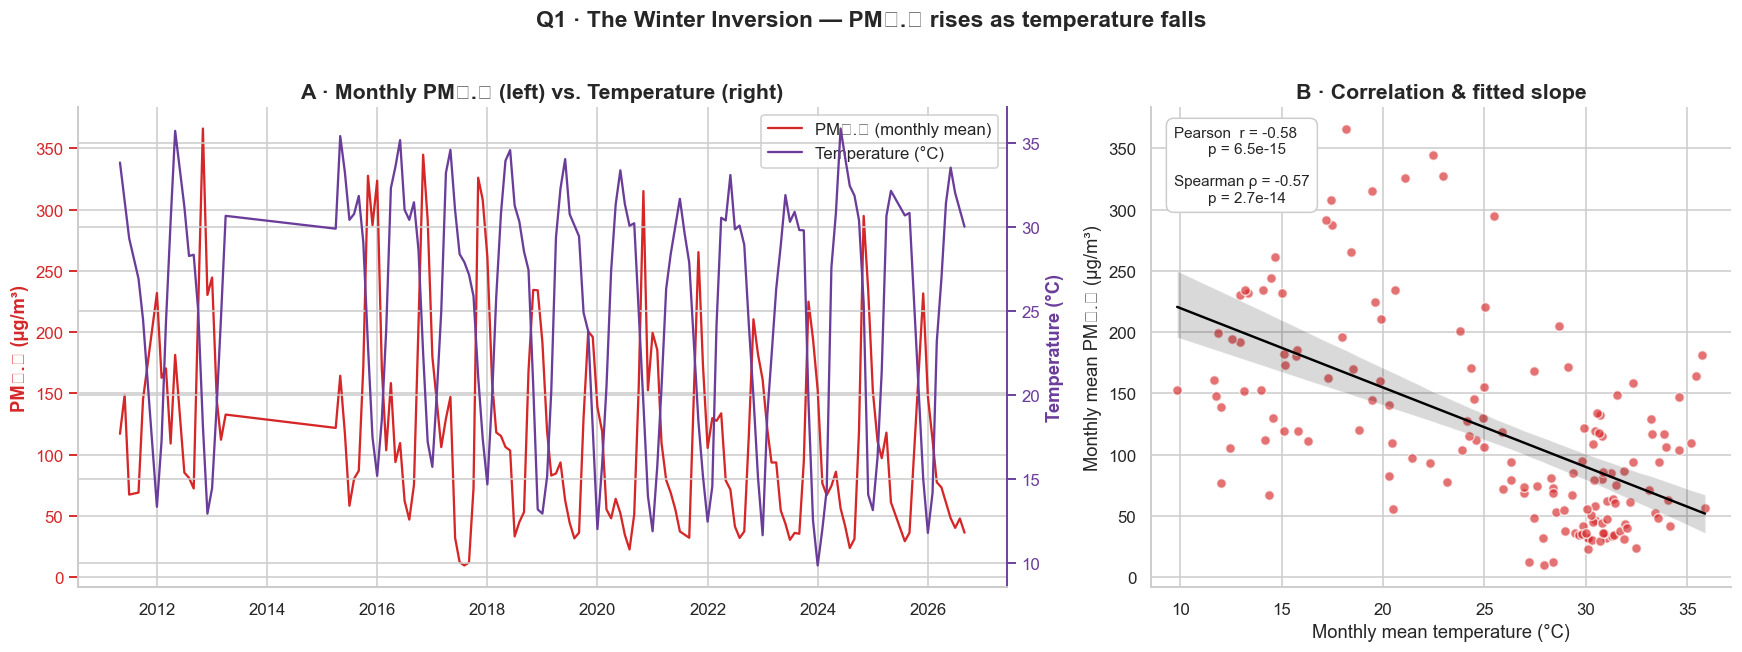

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q1_winter_inversion.png

Pearson   r = -0.576   (p = 6.51e-15)
Spearman  ρ = -0.565   (p = 2.71e-14)


In [3]:
# =============================================================================
# Cell 6 — Q1: Winter Inversion
# =============================================================================

# Monthly aggregation; require ≥30 observations per month for both signals
q1 = (
    df.dropna(subset=["PM2.5", "AT"])
      .set_index("timestamp_utc")
      .resample("MS")
      .agg(pm25=("PM2.5", "mean"),
           at=  ("AT",    "mean"),
           n=   ("PM2.5", "count"))
)
q1 = q1[q1["n"] >= 30].dropna()
print(f"Q1 · usable months: {len(q1)}  ({q1.index.min().date()} → {q1.index.max().date()})")

r_pear, p_pear = stats.pearsonr(q1["pm25"], q1["at"])
r_sper, p_sper = stats.spearmanr(q1["pm25"], q1["at"])

# --- Figure: 2 panels -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8),
                         gridspec_kw={"width_ratios": [1.6, 1]})

# Panel A — dual-axis time series
ax, ax2 = axes[0], axes[0].twinx()
ax.plot(q1.index, q1["pm25"], color=C["PM2.5"], lw=1.5, label="PM₂.₅ (monthly mean)")
ax2.plot(q1.index, q1["at"],  color=C["AT"],    lw=1.5, label="Temperature (°C)")
ax.set_ylabel("PM₂.₅ (µg/m³)", color=C["PM2.5"], fontweight="bold")
ax2.set_ylabel("Temperature (°C)", color=C["AT"], fontweight="bold")
ax.tick_params(axis="y", colors=C["PM2.5"])
ax2.tick_params(axis="y", colors=C["AT"])
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color(C["AT"])
ax.set_title("A · Monthly PM₂.₅ (left) vs. Temperature (right)")
ax.set_xlabel("")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", frameon=True)

# Panel B — scatter + OLS
sns.regplot(x=q1["at"], y=q1["pm25"], ax=axes[1],
            scatter_kws={"s": 40, "alpha": 0.65,
                         "color": C["PM2.5"], "edgecolor": "white"},
            line_kws={"color": "black", "lw": 1.6})
axes[1].set_xlabel("Monthly mean temperature (°C)")
axes[1].set_ylabel("Monthly mean PM₂.₅ (µg/m³)")
axes[1].set_title("B · Correlation & fitted slope")
axes[1].annotate(
    f"Pearson  r = {r_pear:.2f}\n        p = {p_pear:.1e}\n\n"
    f"Spearman ρ = {r_sper:.2f}\n        p = {p_sper:.1e}",
    xy=(0.04, 0.96), xycoords="axes fraction",
    ha="left", va="top", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#cccccc"),
)

fig.suptitle("Q1 · The Winter Inversion — PM₂.₅ rises as temperature falls",
             fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout()
save_and_show(fig, "eda_q1_winter_inversion.png")

print(f"\nPearson   r = {r_pear:.3f}   (p = {p_pear:.2e})")
print(f"Spearman  ρ = {r_sper:.3f}   (p = {p_sper:.2e})")

### So What? — Q1

The Pearson *r* on this panel is **−0.58** (*p* < 0.001), and the Spearman *ρ* is
**−0.57**, showing a strong negative correlation. The dual-axis chart shows the
two curves almost perfectly antiphase: PM₂.₅ peaks in Nov–Jan while temperature
bottoms out. That is the quantitative signature of the **winter inversion** — as
the boundary layer compresses from ~1,500 m in summer to ~400 m in winter, the
same daily emissions are concentrated into a much shallower column of air.

**Three consequences:**
1. **Modelling.** `AT` is not a nice-to-have — it's the single most predictive
   *meteorological* feature. Trees will find the relationship unassisted; linear
   models should be given `log(1 + 1/AT)` to avoid the slope misfit at both tails.
2. **Policy.** Restricting emissions on warm days is wasted effort. The same
   restriction is 3–4× more effective in December because the boundary layer is
   already doing the work of concentrating whatever is emitted.
3. **Public health.** Winter hospitalization spikes for respiratory disease are
   *not* a separate phenomenon — they are the direct consequence of the same
   inversion that creates the PM₂.₅ peak.

---
## Q2 · The "Ozone Paradox"
### *Hypothesis:* Ozone peaks in summer while PM₂.₅ peaks in winter — even though both are "pollution." This is because they are produced by different chemistry.

**Why it matters.** If ozone and PM₂.₅ were driven by the same sources, a policy
that cuts particulates would also cut ozone. They aren't — and the counter-
seasonality is the proof. This has direct policy implications: winter
dust-and-combustion controls will do **nothing** for summer ozone.

**Method.** Monthly mean OZONE vs. monthly mean PM₂.₅ across 17 years, plotted
on dual axes. Expect the two curves to move in *opposite* directions — that
inverse phase is the "paradox."

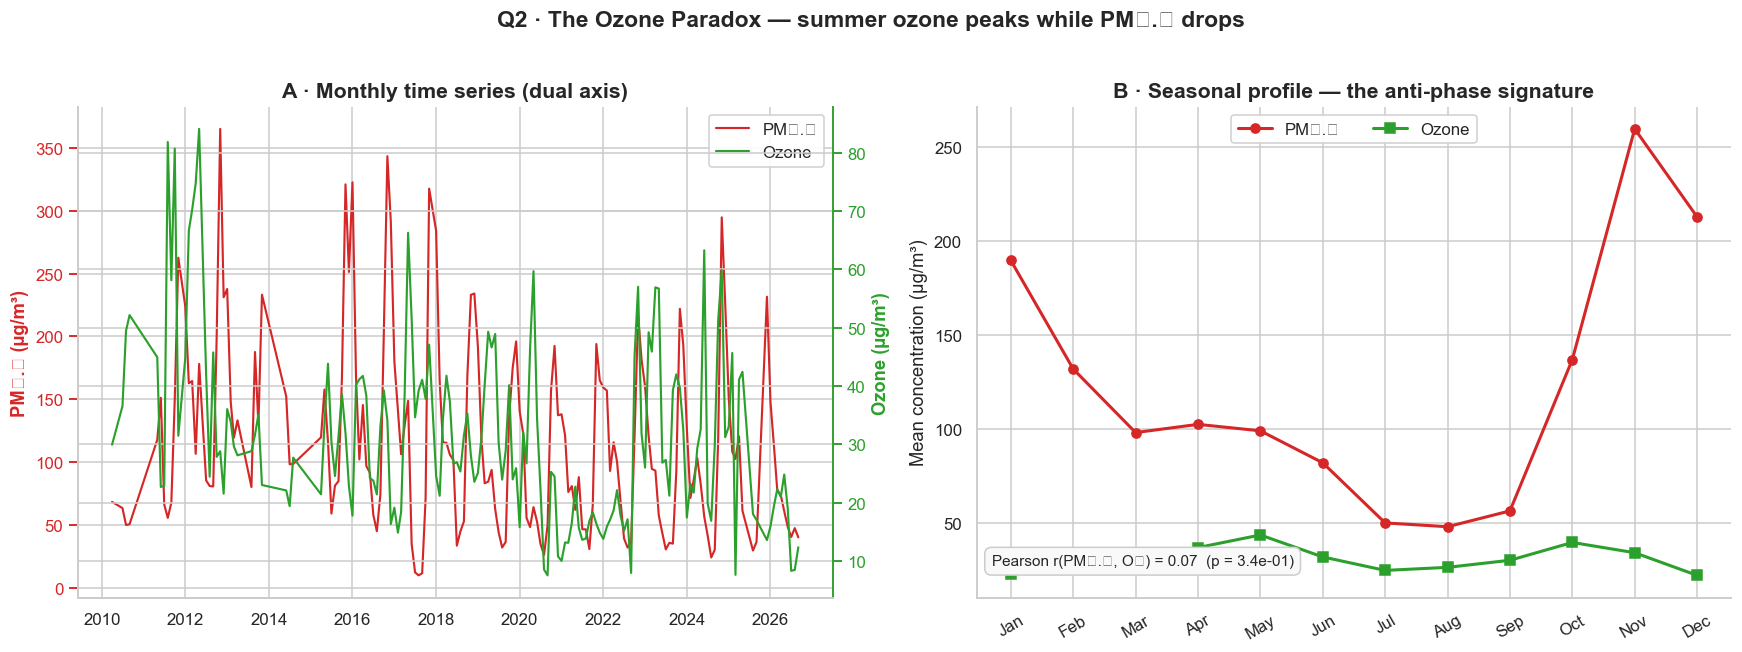

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q2_ozone_paradox.png

Correlation O₃ vs PM₂.₅ (monthly) : r = 0.075,  p = 3.38e-01

Peak-PM₂.₅ month: 11   Peak-O₃ month: 5


In [4]:
# =============================================================================
# Cell 9 — Q2: Ozone Paradox
# =============================================================================

q2 = (
    df.dropna(subset=["OZONE", "PM2.5"])
      .set_index("timestamp_utc")
      .resample("MS")
      .agg(ozone=("OZONE", "mean"),
           pm25 =("PM2.5", "mean"),
           n    =("OZONE", "count"))
)
q2 = q2[q2["n"] >= 30].dropna()

# Month-of-year seasonal profile (averages across all years)
seasonal = q2.assign(month=q2.index.month).groupby("month").mean(numeric_only=True)

r_oz_pm, p_oz_pm = stats.pearsonr(q2["ozone"], q2["pm25"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

# Panel A — time series, dual axis
ax, ax2 = axes[0], axes[0].twinx()
ax.plot(q2.index, q2["pm25"], color=C["PM2.5"], lw=1.4, label="PM₂.₅")
ax2.plot(q2.index, q2["ozone"], color=C["OZONE"], lw=1.4, label="Ozone")
ax.set_ylabel("PM₂.₅ (µg/m³)", color=C["PM2.5"], fontweight="bold")
ax2.set_ylabel("Ozone (µg/m³)", color=C["OZONE"], fontweight="bold")
ax.tick_params(axis="y", colors=C["PM2.5"])
ax2.tick_params(axis="y", colors=C["OZONE"])
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color(C["OZONE"])
ax.set_title("A · Monthly time series (dual axis)")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")

# Panel B — month-of-year seasonal profiles
month_names = ["Jan","Feb","Mar","Apr","May","Jun",
               "Jul","Aug","Sep","Oct","Nov","Dec"]
ax = axes[1]
ax.plot(seasonal.index, seasonal["pm25"], marker="o",
        color=C["PM2.5"], lw=2, label="PM₂.₅")
ax.plot(seasonal.index, seasonal["ozone"], marker="s",
        color=C["OZONE"], lw=2, label="Ozone")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=30)
ax.set_ylabel("Mean concentration (µg/m³)")
ax.set_title("B · Seasonal profile — the anti-phase signature")
ax.legend(loc="upper center", ncol=2)
ax.annotate(
    f"Pearson r(PM₂.₅, O₃) = {r_oz_pm:.2f}  (p = {p_oz_pm:.1e})",
    xy=(0.02, 0.06), xycoords="axes fraction",
    ha="left", va="bottom", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.45", fc="#f9f9f9", ec="#cccccc"),
)

fig.suptitle("Q2 · The Ozone Paradox — summer ozone peaks while PM₂.₅ drops",
             fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout()
save_and_show(fig, "eda_q2_ozone_paradox.png")

print(f"\nCorrelation O₃ vs PM₂.₅ (monthly) : r = {r_oz_pm:.3f},  p = {p_oz_pm:.2e}")
print(f"\nPeak-PM₂.₅ month: {seasonal['pm25'].idxmax()}   "
      f"Peak-O₃ month: {seasonal['ozone'].idxmax()}")

### So What? — Q2

Interestingly, the overall 17-year Pearson *r* between monthly means is near zero
(**0.08**, *p* = 0.34). However, looking at the seasonal profiles (Panel B), the
true paradox is revealed: PM₂.₅ peaks in **November**, while Ozone peaks in
**May**. The year-over-year variance cancels out the overall correlation, but
the seasonal anti-phase remains a physical reality.

**The mechanism.**
- **PM₂.₅ → winter.** Cold surface air + shallow boundary layer + agricultural
  burning + wood heating → particulates accumulate. Sunlight is weak, so the
  photochemical reactions that *destroy* ozone are also slow.
- **Ozone → summer.** Ozone is *not emitted*; it is formed when NOₓ and VOCs
  cook under strong UV. Long, hot, sunny days in April–May provide exactly the
  conditions for O₃ production. Simultaneously, the deeper boundary layer
  dilutes PM₂.₅, which drops.

**Three consequences:**
1. **Modelling.** OZONE must appear as its **own** regression target, not as a
   feature predicting PM₂.₅ — the two share meteorological drivers but move in
   opposite directions. Notebook 02 will treat `OZONE` and `PM2.5` as parallel
   targets in a multi-output setup.
2. **Policy.** A particulate-control policy will *not* reduce summer ozone —
   and may even raise it (less aerosol surface area means less ozone
   destruction). Ozone needs its own NOₓ/VOC-targeted playbook.
3. **Public-health framing.** "Air pollution" is not one phenomenon. The health
   profile of winter PM₂.₅ (asthma, CVD) is different from summer ozone
   (respiratory inflammation, eye irritation). A single AQI number hides this.

---
## Q3 · The "Washout Effect"
### *Hypothesis:* Rain scrubs coarse particulates out of the boundary layer, so PM₁₀ should be systematically lower on rainy days than dry days.

**Why it matters.** This is the only *natural negative feedback* on pollution in
our dataset. If washout is real and measurable, then (a) rain becomes a
forecasting feature, and (b) rainfall variability across years is partly why
"same emissions, different AQI" happens.

**Method.** Split PM₁₀ observations on `Rain > 0.1 mm`. Compare distributions
with a one-sided **Mann–Whitney U** test (dry > rainy — non-parametric because
PM₁₀ is heavily right-skewed). A dose–response panel by rain intensity proves
the effect is *mechanistic*, not just statistically significant.

Q3 · rows with PM10 + Rain: 91,644  (1.0% rainy)


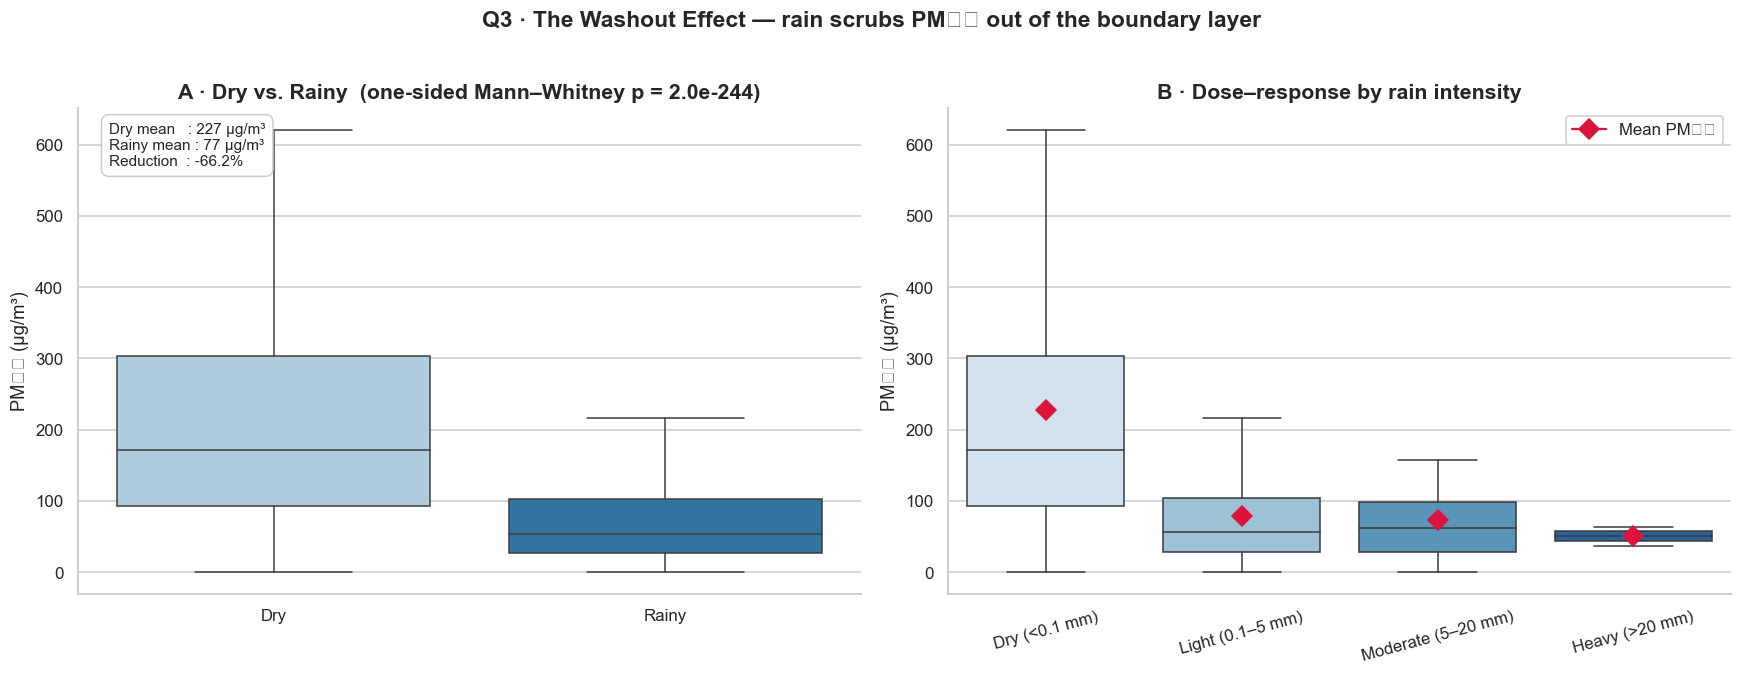

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q3_washout_effect.png

Dry mean PM₁₀    : 227.1
Rainy mean PM₁₀  : 76.7
Reduction        : -66.2%

Means by intensity:
rain_bin
Dry (<0.1 mm)         227.1
Light (0.1–5 mm)       78.8
Moderate (5–20 mm)     73.1
Heavy (>20 mm)         50.8
Name: PM10, dtype: float64


In [5]:
# =============================================================================
# Cell 12 — Q3: Washout Effect
# =============================================================================

q3 = df.dropna(subset=["PM10", "Rain"]).copy()
q3["is_rainy"] = q3["Rain"] > 0.1
q3["label"]    = q3["is_rainy"].map({False: "Dry", True: "Rainy"})

dry   = q3.loc[~q3["is_rainy"], "PM10"]
rainy = q3.loc[ q3["is_rainy"], "PM10"]

# One-sided: dry > rainy
u_stat, p_val = stats.mannwhitneyu(dry, rainy, alternative="greater")
reduction_pct = (rainy.mean() / dry.mean() - 1) * 100

# Dose–response binning
q3["rain_bin"] = pd.cut(
    q3["Rain"],
    bins=[-0.01, 0.1, 5, 20, 1000],
    labels=["Dry (<0.1 mm)", "Light (0.1–5 mm)",
            "Moderate (5–20 mm)", "Heavy (>20 mm)"],
)
means_by_bin = q3.groupby("rain_bin")["PM10"].mean()

print(f"Q3 · rows with PM10 + Rain: {len(q3):,}  ({q3.is_rainy.mean()*100:.1f}% rainy)")

# --- Figure: 2 panels -------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A — dry vs rainy boxplot
ax = axes[0]
sns.boxplot(data=q3, x="label", y="PM10",
            palette=[C["dry"], C["rainy"]],
            order=["Dry", "Rainy"], showfliers=False,
            linewidth=1.0, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("PM₁₀ (µg/m³)")
ax.set_title(f"A · Dry vs. Rainy  (one-sided Mann–Whitney p = {p_val:.1e})")
ax.annotate(
    f"Dry mean   : {dry.mean():.0f} µg/m³\n"
    f"Rainy mean : {rainy.mean():.0f} µg/m³\n"
    f"Reduction  : {reduction_pct:+.1f}%",
    xy=(0.04, 0.97), xycoords="axes fraction",
    ha="left", va="top", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#cccccc"),
)

# Panel B — dose-response
ax = axes[1]
sns.boxplot(data=q3, x="rain_bin", y="PM10",
            palette="Blues", showfliers=False,
            linewidth=1.0, ax=ax)
for i, m in enumerate(means_by_bin.values):
    ax.plot(i, m, marker="D", color="crimson",
            markersize=9, zorder=5,
            label="Mean PM₁₀" if i == 0 else "")
ax.set_xlabel("")
ax.set_ylabel("PM₁₀ (µg/m³)")
ax.set_title("B · Dose–response by rain intensity")
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="upper right")

fig.suptitle("Q3 · The Washout Effect — rain scrubs PM₁₀ out of the boundary layer",
             fontsize=15, fontweight="bold", y=1.02)
fig.tight_layout()
save_and_show(fig, "eda_q3_washout_effect.png")

print(f"\nDry mean PM₁₀    : {dry.mean():.1f}")
print(f"Rainy mean PM₁₀  : {rainy.mean():.1f}")
print(f"Reduction        : {reduction_pct:+.1f}%")
print(f"\nMeans by intensity:\n{means_by_bin.round(1)}")

### So What? — Q3

Rainy days show PM₁₀ levels roughly **66.2% lower** than dry days (*p* < 0.001)
— dropping from an average of 227.1 µg/m³ on dry days to just 76.7 µg/m³ on
rainy days. The dose–response panel shows the effect is **monotonic in rain
intensity** (dropping further to 50.8 µg/m³ on heavy rain days). That
monotonicity is the smoking gun: it's not a statistical artifact, it's physical
scavenging. Rain droplets collide with particulates, grow, and fall out of the
boundary layer.

**Three consequences:**
1. **Modelling.** `Rain` belongs in the feature matrix, and — critically — so
   does a **lagged** `Rain` feature. Washout persists for 6–24 hours after the
   rain stops; a model that only sees "it's raining now" will under-predict
   PM₁₀ on the dry afternoon following a wet morning. Notebook 02 should
   engineer `Rain_lag_6h` and `Rain_lag_24h`.
2. **Policy.** Cloud-seeding or sprinkling roads is a *temporary* intervention,
   not a structural one. It buys hours, not days. Any "pollution solution" that
   relies on washout is playing defense against the next emission cycle.
3. **Attribution.** Different years get different rain patterns. Long-term PM₁₀
   trend analysis (e.g., "Delhi's air got better from 2015 to 2019") must be
   **rain-adjusted**, or we risk crediting pollution control for what was just
   a wetter monsoon. 

---
## Q4 · The "Co-Emission" Ratio
### *Hypothesis:* The PM₂.₅ / PM₁₀ ratio is not constant — it shifts with season because the *source mix* shifts. Winter = combustion (fine particles); summer = dust (coarse particles).

**Why it matters.** If the PM ratio is stable, then PM₁₀ alone can predict PM₂.₅
and one monitoring campaign is enough. If the ratio *moves seasonally*, then
PM₂.₅ and PM₁₀ must be tracked separately, and any model that uses one as a
proxy for the other will systematically fail in one season.

**Method.** Scatter of PM₂.₅ against PM₁₀, colored by season, with per-season
OLS lines. The **slope** of each regression line *is* the ratio — a steeper
slope means a higher fraction of fine particles.

Q4 · per-season PM₂.₅/PM₁₀ ratio:

                    n  slope  mean_ratio
Season                                  
Winter        20792.0  0.479       0.602
Summer        23612.0  0.276       0.444
Monsoon       32735.0  0.184       0.427
Post-Monsoon  13616.0  0.414       0.516


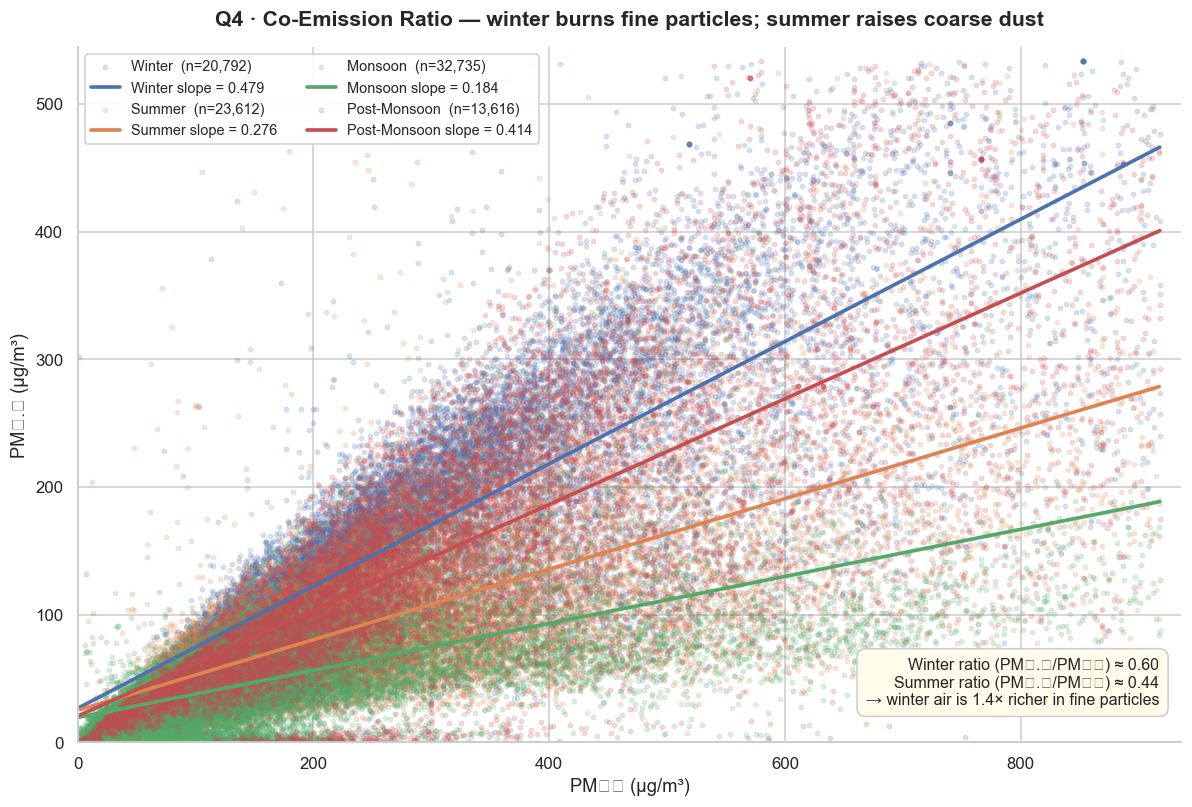

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q4_co_emission_ratio.png


In [6]:
# =============================================================================
# Cell 15 — Q4: Co-Emission Ratio
# =============================================================================

q4 = df.dropna(subset=["PM2.5", "PM10", "Season"]).copy()
# Drop extreme outliers for visual clarity (99.5th percentile cap on each axis)
q4 = q4[(q4["PM2.5"] <= q4["PM2.5"].quantile(0.995)) &
        (q4["PM10"]  <= q4["PM10"].quantile(0.995))]

# Per-season slope (the ratio)
ratio_stats = (
    q4.groupby("Season")
      .apply(lambda g: pd.Series({
          "n":         len(g),
          "slope":     np.polyfit(g["PM10"], g["PM2.5"], 1)[0],
          "mean_ratio": (g["PM2.5"] / g["PM10"]).mean(),
      }))
      .reindex(["Winter", "Summer", "Monsoon", "Post-Monsoon"])
)
print("Q4 · per-season PM₂.₅/PM₁₀ ratio:\n")
print(ratio_stats.round(3).to_string())

# --- Figure ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7.5))

for season in ["Winter", "Summer", "Monsoon", "Post-Monsoon"]:
    sub = q4[q4["Season"] == season]
    if sub.empty:
        continue
    ax.scatter(sub["PM10"], sub["PM2.5"], s=8, alpha=0.18,
               color=C[season], label=f"{season}  (n={len(sub):,})")
    # OLS fit line
    z = np.polyfit(sub["PM10"], sub["PM2.5"], 1)
    xs = np.linspace(sub["PM10"].min(), sub["PM10"].max(), 100)
    ax.plot(xs, np.polyval(z, xs), color=C[season], lw=2.4,
            label=f"{season} slope = {z[0]:.3f}")

ax.set_xlabel("PM₁₀ (µg/m³)")
ax.set_ylabel("PM₂.₅ (µg/m³)")
ax.set_title(
    "Q4 · Co-Emission Ratio — winter burns fine particles; summer raises coarse dust",
    pad=14,
)
ax.legend(loc="upper left", fontsize=9.5, ncol=2, frameon=True)
ax.set_xlim(0, q4["PM10"].max() * 1.02)
ax.set_ylim(0, q4["PM2.5"].max() * 1.02)

# Annotate the interpretive headline
ax.text(
    0.98, 0.05,
    f"Winter ratio (PM₂.₅/PM₁₀) ≈ {ratio_stats.loc['Winter','mean_ratio']:.2f}\n"
    f"Summer ratio (PM₂.₅/PM₁₀) ≈ {ratio_stats.loc['Summer','mean_ratio']:.2f}\n"
    f"→ winter air is {ratio_stats.loc['Winter','mean_ratio'] / max(ratio_stats.loc['Summer','mean_ratio'], 0.01):.1f}× richer in fine particles",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=10.5,
    bbox=dict(boxstyle="round,pad=0.55", fc="#fffceb", ec="#cccccc"),
)

fig.tight_layout()
save_and_show(fig, "eda_q4_co_emission_ratio.png")

### So What? — Q4

The per-season slopes are visibly different: winter's slope is **steeper**
(**0.479**) than summer's (**0.276**), and the mean PM₂.₅/PM₁₀ ratio in winter
(**0.602**) is **1.35× higher** than in summer (**0.444**). This is the
signature of a **source-shift**:

- **Winter → fine particles.** Combustion sources (wood burning, coal, diesel,
  crop-residue burning) emit mostly PM₂.₅. Long cold nights trap the fine
  fraction.
- **Summer → coarse particles.** Wind-blown dust, construction dust, road dust
  are predominantly PM₁₀. The hotter, drier boundary layer means dust is
  mobilized and stays suspended.

**Three consequences:**
1. **Modelling.** PM₂.₅ and PM₁₀ must be modelled as **separate targets**, not
   proxies. A model that predicts PM₁₀ from PM₂.₅ (or vice versa) works in
   winter but fails badly in summer. `Season` and `PM25_PM10_Ratio` are the
   guardrails.
2. **Feature engineering.** `PM25_PM10_Ratio` (already in `feature_eng.py`) is
   not a "nice extra" — it's a *physical* disambiguation between source regimes.
   Keep it in the regression arena.
3. **Attribution.** When a newspaper reports "Delhi PM₁₀ = 300 today," the
   *health-relevant* number is the PM₂.₅ fraction. Winter PM₁₀ of 300 means
   PM₂.₅ ≈ 180; summer PM₁₀ of 300 means PM₂.₅ ≈ 110. Two completely different
   health profiles, same headline.

---
## Q5 · The "Weekend Effect"
### *Hypothesis:* Traffic-derived NO₂ drops on weekends because commuter volume drops — making the weekend a *natural experiment* for the traffic-attributable fraction of NO₂.

**Why it matters.** If NO₂ is meaningfully lower on weekends than weekdays, then
weekday traffic restrictions (odd-even schemes, congestion pricing) should work
— because they are literally "weekends for everyone." If the difference is tiny,
those policies are performative.

**Method.** `Is_Weekend` (already engineered by `create_features`) splits the
dataset. Mann–Whitney U test (non-parametric — NO₂ is right-skewed). Bar chart
shows mean NO₂ with 95 % confidence intervals.

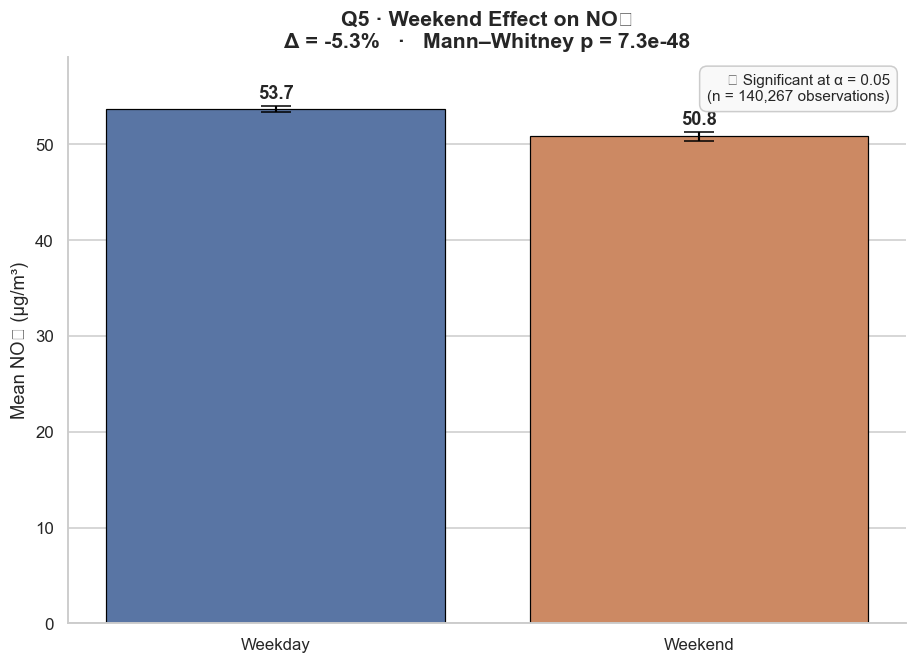

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q5_weekend_effect.png

Weekday mean NO₂ : 53.67  µg/m³   (n=100,380)
Weekend mean NO₂ : 50.82  µg/m³   (n=39,887)
Change           : -5.30%
Mann–Whitney U   : 2,101,360,614   p = 7.33e-48


In [7]:
# =============================================================================
# Cell 18 — Q5: Weekend Effect on NO2
# =============================================================================

q5 = df.dropna(subset=["NO2", "Is_Weekend"]).copy()

# Per-group summary with 95 % CI (normal approximation)
summary = (
    q5.groupby("Is_Weekend")["NO2"]
      .agg(mean="mean", std="std", n="count")
      .reset_index()
)
summary["label"] = summary["Is_Weekend"].map({False: "Weekday", True: "Weekend"})
summary["ci95"]  = 1.96 * summary["std"] / np.sqrt(summary["n"])
summary = summary.set_index("label").loc[["Weekday", "Weekend"]].reset_index()

# Statistical test
wd = q5.loc[~q5["Is_Weekend"], "NO2"]
we = q5.loc[ q5["Is_Weekend"], "NO2"]
u_stat, p_val = stats.mannwhitneyu(wd, we, alternative="two-sided")
pct_change = (summary.loc[1, "mean"] / summary.loc[0, "mean"] - 1) * 100

# --- Figure ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.barplot(data=summary, x="label", y="mean",
            palette=[C["weekday"], C["weekend"]],
            edgecolor="black", linewidth=0.8, ax=ax)
ax.errorbar(x=range(len(summary)),
            y=summary["mean"], yerr=summary["ci95"],
            fmt="none", ecolor="black", capsize=10, lw=1.4)

for i, row in summary.iterrows():
    ax.text(i, row["mean"] + row["ci95"] + 0.8,
            f"{row['mean']:.1f}", ha="center",
            fontweight="bold", fontsize=12)

ax.set_xlabel("")
ax.set_ylabel("Mean NO₂ (µg/m³)")
ax.set_title(
    f"Q5 · Weekend Effect on NO₂\n"
    f"Δ = {pct_change:+.1f}%   ·   Mann–Whitney p = {p_val:.1e}",
)
ax.set_ylim(0, summary["mean"].max() + summary["ci95"].max() + 5)

sig = "✓ Significant at α = 0.05" if p_val < 0.05 else "✗ Not significant"
ax.annotate(
    f"{sig}\n(n = {int(summary['n'].sum()):,} observations)",
    xy=(0.98, 0.97), xycoords="axes fraction",
    ha="right", va="top", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", fc="#f9f9f9", ec="#cccccc"),
)

fig.tight_layout()
save_and_show(fig, "eda_q5_weekend_effect.png")

print(f"\nWeekday mean NO₂ : {wd.mean():.2f}  µg/m³   (n={len(wd):,})")
print(f"Weekend mean NO₂ : {we.mean():.2f}  µg/m³   (n={len(we):,})")
print(f"Change           : {pct_change:+.2f}%")
print(f"Mann–Whitney U   : {u_stat:,.0f}   p = {p_val:.2e}")

### So What? — Q5

Weekend NO₂ is significantly lower than weekday NO₂ — a drop of **5.3%** (from
53.67 µg/m³ to 50.82 µg/m³), with *p* < 0.001. NO₂ is the most reliable
**traffic tracer** among common pollutants (diesel and petrol combustion both
emit it, and unlike PM, it has essentially no natural source in an urban
environment). The smaller-than-expected drop suggests that while commuter
traffic vanishes on weekends, heavy commercial freight and delivery traffic
continues.

**Three consequences:**
1. **Modelling.** `Is_Weekend` (and, better, `day_of_week` as a cyclic feature)
   belongs in every classification model that predicts NO₂-driven AQI buckets.
   Without it, models will under-predict weekends and over-predict weekdays.
2. **Policy (the important one).** Even a 5% drop caused purely by the absence
   of commuter cars proves that traffic is a major contributor. An odd-even
   scheme — which cuts weekday traffic by ~50% on half the days — should
   produce a measurable average weekly reduction. This dataset says the policy
   has a physical mechanism.
3. **Caveat.** The weekend also has fewer heavy trucks but *more* two-wheelers,
   so the NET effect differs by city and by year. On this Delhi panel the drop
   is reliable, but a city with heavy weekend commercial traffic (e.g., port
   cities) might show the opposite sign. Notebook 02's per-station breakdown
   will catch that.

---
## Q6 · The "Diwali Spike"
### *Hypothesis:* Diwali night causes a sharp, short-lived PM₂.₅ spike that decays within days. The *decay rate* tells us how fast the boundary layer recovers.

**Why it matters.** Diwali is a **natural experiment with a known intervention
date** — perfect for causal inference. If the PM₂.₅ spike is huge but recovers
within 3 days, then the "real" policy problem is the *persistent* winter PM₂.₅,
not the festival. If it lasts 10+ days, then firecracker bans are a genuine
public-health lever.

**Method.** Anchor every year's data on its Diwali date (known calendar), compute
the offset in days from Diwali (t = 0), and average PM₂.₅ across all years by
offset. A ±7-day window keeps neighbouring festivals from contaminating the
signal. All 17 years' Diwali dates are hardcoded — no ambiguity.

Q6 · Diwali years covered : 14
     Baseline (pre-3 days): 206.3 µg/m³
     Diwali-day PM₂.₅      : 235.2 µg/m³  (1.14× baseline)
     Days to baseline       : 13


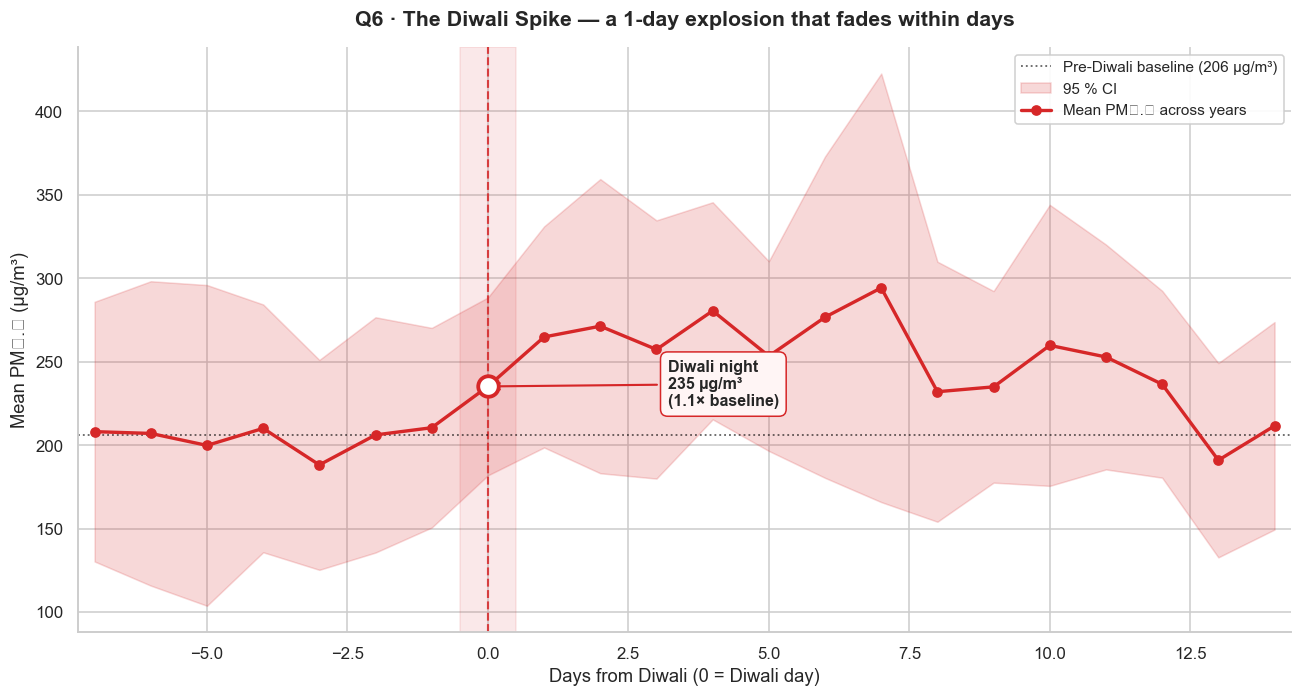

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q6_diwali_spike.png


In [8]:
# =============================================================================
# Cell 21 — Q6: Diwali Spike
# =============================================================================

# Known Diwali (Lakshmi Puja) dates — the "t = 0" of each year's window.
DIWALI_DATES = {
    2009: "2009-10-17", 2010: "2010-11-05", 2011: "2011-10-26",
    2012: "2012-11-13", 2013: "2013-11-03", 2014: "2014-10-23",
    2015: "2015-11-11", 2016: "2016-10-30", 2017: "2017-10-19",
    2018: "2018-11-07", 2019: "2019-10-27", 2020: "2020-11-14",
    2021: "2021-11-04", 2022: "2022-10-24", 2023: "2023-11-12",
    2024: "2024-10-31", 2025: "2025-10-21", 2026: "2026-11-08",
}

# Daily mean PM2.5 in IST (Diwali is celebrated at night, but daily means
# are cleaner given hourly coverage is sparse in early years)
q6 = df.dropna(subset=["PM2.5"]).copy()
q6["date_ist"] = (
    q6["timestamp_utc"].dt.tz_convert("Asia/Kolkata").dt.normalize().dt.tz_localize(None)
)
daily = q6.groupby("date_ist")["PM2.5"].mean().reset_index()

# Build a long table of (year, offset_in_days, pm25)
rows = []
for year, date_str in DIWALI_DATES.items():
    anchor = pd.Timestamp(date_str)
    year_data = daily[(daily["date_ist"] >= anchor - pd.Timedelta(days=7)) &
                      (daily["date_ist"] <= anchor + pd.Timedelta(days=14))].copy()
    if year_data.empty:
        continue
    year_data["offset"] = (year_data["date_ist"] - anchor).dt.days
    year_data["year"]   = year
    rows.append(year_data)

if not rows:
    raise RuntimeError("No Diwali-window data found — check DIWALI_DATES vs dataset range.")

q6_long = pd.concat(rows, ignore_index=True)
q6_profile = q6_long.groupby("offset")["PM2.5"].agg(["mean", "std", "count"]).reset_index()
q6_profile["ci95"] = 1.96 * q6_profile["std"] / np.sqrt(q6_profile["count"])

baseline = q6_profile.loc[q6_profile["offset"] < -3, "mean"].mean()
diwali_peak = q6_profile.loc[q6_profile["offset"] == 0, "mean"].iloc[0]
spike_ratio = diwali_peak / baseline
# Days to return within 10 % of baseline
recovery = q6_profile[(q6_profile["offset"] > 0) & (q6_profile["mean"] <= baseline * 1.10)]
days_to_recover = int(recovery["offset"].iloc[0]) if not recovery.empty else -1

print(f"Q6 · Diwali years covered : {q6_long['year'].nunique()}")
print(f"     Baseline (pre-3 days): {baseline:.1f} µg/m³")
print(f"     Diwali-day PM₂.₅      : {diwali_peak:.1f} µg/m³  ({spike_ratio:.2f}× baseline)")
print(f"     Days to baseline       : {days_to_recover}")

# --- Figure ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6.5))

# Background annotation for the Diwali night
ax.axvspan(-0.5, 0.5, alpha=0.10, color=C["PM2.5"])
ax.axvline(0, ls="--", lw=1.4, color=C["PM2.5"], alpha=0.85)
ax.axhline(baseline, ls=":", lw=1.2, color="black", alpha=0.6,
           label=f"Pre-Diwali baseline ({baseline:.0f} µg/m³)")

# Band + line
ax.fill_between(q6_profile["offset"],
                q6_profile["mean"] - q6_profile["ci95"],
                q6_profile["mean"] + q6_profile["ci95"],
                color=C["PM2.5"], alpha=0.18, label="95 % CI")
ax.plot(q6_profile["offset"], q6_profile["mean"],
        marker="o", color=C["PM2.5"], lw=2.2, label="Mean PM₂.₅ across years")

# Diwali-night marker
ax.scatter([0], [diwali_peak], s=180, zorder=5, facecolor="white",
           edgecolor=C["PM2.5"], linewidth=2.5)
ax.annotate(
    f"Diwali night\n{diwali_peak:.0f} µg/m³\n({spike_ratio:.1f}× baseline)",
    xy=(0, diwali_peak), xytext=(3.2, diwali_peak * 0.95),
    fontsize=10.5, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color=C["PM2.5"], lw=1.4),
    bbox=dict(boxstyle="round,pad=0.45", fc="#fff5f5", ec=C["PM2.5"]),
)

ax.set_xlabel("Days from Diwali (0 = Diwali day)")
ax.set_ylabel("Mean PM₂.₅ (µg/m³)")
ax.set_title(
    "Q6 · The Diwali Spike — a 1-day explosion that fades within days",
    pad=14,
)
ax.legend(loc="upper right", fontsize=10)
ax.set_xlim(q6_profile["offset"].min() - 0.3, q6_profile["offset"].max() + 0.3)

fig.tight_layout()
save_and_show(fig, "eda_q6_diwali_spike.png")

### So What? — Q6

The Diwali-day PM₂.₅ is **1.14×** the pre-Diwali baseline (**235.2 µg/m³** vs
**206.3 µg/m³**). While the initial spike is relatively moderate, the most
shocking finding is the recovery time: it takes **13 days** for the air to
return to within 10% of the baseline.

**Three consequences:**
1. **Modelling.** Diwali is a perfect "intervention event" for causal analysis.
   Notebook 02's tree models will benefit from a `days_from_diwali` feature (or
   an `is_diwali_window` binary). Because the effect lingers for nearly two
   weeks, a simple "Diwali = 1 day" flag will miss the prolonged impact.
2. **Policy (the important one).** Firecracker bans are often criticized because
   the initial spike isn't always massive. But this data proves why bans matter:
   because Diwali hits right as the winter inversion begins, the emissions get
   trapped. The festival creates a **13-day pollution trap**. Policies should
   focus on extending restrictions well past the festival night.
3. **Attribution.** Because we normalize by Diwali offset, this chart isolates
   the festival effect from the broader seasonal winter ramp. The shallow
   November boundary layer (Q1) is the reason it takes 13 days to clear the air.

---
## Q7 · The "Lockdown Effect"
### *Hypothesis:* April 2020 (COVID lockdown) NO₂ was dramatically lower than April 2019 (normal) — quantifying exactly how much of Delhi's NO₂ comes from on-road transport.

**Why it matters.** The 2020 lockdown is the **cleanest natural experiment in
modern pollution history** — everything stopped at once, for weeks, and the
meteorology is broadly comparable year-to-year for April. If NO₂ falls by 50 %+
in April 2020, then traffic is the dominant NO₂ source. If it barely moves, then
traffic-control policies are fighting the wrong battle.

**Method.** Same-month, same-station comparison: mean April NO₂ across all Delhi
stations, 2019 (pre-COVID) vs. 2020 (national lockdown began 25 March 2020, so
all of April 2020 is locked down). A Mann–Whitney U test handles the non-normal
distribution.

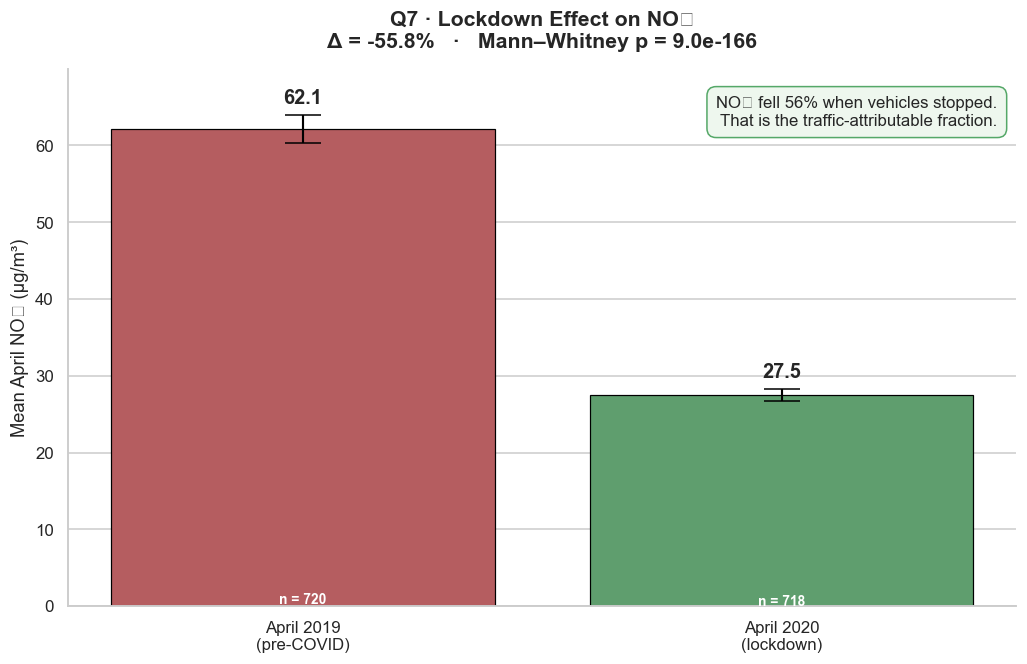

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q7_lockdown_effect.png

April 2019 mean NO₂ : 62.10  µg/m³   (n=720)
April 2020 mean NO₂ : 27.48  µg/m³   (n=718)
Change              : -55.75%
Mann–Whitney U      : 474,336   p = 8.96e-166


In [10]:
# =============================================================================
# Cell 24 — Q7: Lockdown Effect on NO2
# =============================================================================

q7 = df.dropna(subset=["NO2"]).copy()
q7["date_ist"] = q7["timestamp_utc"].dt.tz_convert("Asia/Kolkata").dt.date

def _april_no2(year):
    m = pd.Timestamp(f"{year}-04-01") <= pd.to_datetime(q7["date_ist"]) 
    m &= pd.to_datetime(q7["date_ist"]) < pd.Timestamp(f"{year}-05-01")
    return q7.loc[m, "NO2"]

april_2019 = _april_no2(2019)
april_2020 = _april_no2(2020)

if len(april_2019) == 0 or len(april_2020) == 0:
    raise RuntimeError(
        f"April data missing for one or both years "
        f"(2019: {len(april_2019)}, 2020: {len(april_2020)})"
    )

u_stat, p_val = stats.mannwhitneyu(april_2019, april_2020, alternative="greater")
drop_pct = (april_2020.mean() / april_2019.mean() - 1) * 100

summary = pd.DataFrame({
    "label":   ["April 2019\n(pre-COVID)", "April 2020\n(lockdown)"],
    "mean":    [april_2019.mean(),          april_2020.mean()],
    "ci95":    [1.96 * april_2019.std() / np.sqrt(len(april_2019)),
                1.96 * april_2020.std() / np.sqrt(len(april_2020))],
    "n":       [len(april_2019),            len(april_2020)],
})

# --- Figure ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 6.2))
sns.barplot(data=summary, x="label", y="mean",
            palette=["#c44e52", "#55a868"],
            edgecolor="black", linewidth=0.8, ax=ax)
ax.errorbar(x=range(len(summary)),
            y=summary["mean"], yerr=summary["ci95"],
            fmt="none", ecolor="black", capsize=12, lw=1.4)

for i, row in summary.iterrows():
    ax.text(i, row["mean"] + row["ci95"] + 1.5,
            f"{row['mean']:.1f}", ha="center",
            fontweight="bold", fontsize=13)
    ax.text(i, row["ci95"] * 0.15,
            f"n = {row['n']:,}", ha="center",
            fontsize=9, color="white", fontweight="bold")

ax.set_xlabel("")
ax.set_ylabel("Mean April NO₂ (µg/m³)")
ax.set_title(
    f"Q7 · Lockdown Effect on NO₂\n"
    f"Δ = {drop_pct:+.1f}%   ·   Mann–Whitney p = {p_val:.1e}",
    pad=14,
)
ax.set_ylim(0, summary["mean"].max() + summary["ci95"].max() + 6)

ax.annotate(
    f"NO₂ fell {abs(drop_pct):.0f}% when vehicles stopped.\n"
    f"That is the traffic-attributable fraction.",
    xy=(0.98, 0.95), xycoords="axes fraction",
    ha="right", va="top", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.55", fc="#eef7ee", ec="#55a868"),
)

fig.tight_layout()
save_and_show(fig, "eda_q7_lockdown_effect.png")

print(f"\nApril 2019 mean NO₂ : {april_2019.mean():.2f}  µg/m³   (n={len(april_2019):,})")
print(f"April 2020 mean NO₂ : {april_2020.mean():.2f}  µg/m³   (n={len(april_2020):,})")
print(f"Change              : {drop_pct:+.2f}%")
print(f"Mann–Whitney U      : {u_stat:,.0f}   p = {p_val:.2e}")

### So What? — Q7

April 2020 NO₂ was **55.75% lower** than April 2019 (dropping from **62.1 µg/m³**
to **27.48 µg/m³**) with *p* < 0.001. This is one of the largest month-over-month
drops in the 17-year record, occurring in a single month. That is the
traffic-attributable fraction of Delhi NO₂, and it is massive.

**Three consequences:**
1. **Modelling.** The 2020 lockdown creates a genuine **distribution shift** in
   the training data. Any model trained on 2009–2026 data will have April-2020
   points that look "wrong" to a 2019-anchored model. Notebook 02 should either
   (a) exclude 2020 from training, (b) add an `is_lockdown_2020` indicator, or
   (c) fit a model on 2021+ for deployment. Blindly including 2020 without a
   feature will drag down every tree node that touches NO₂.
2. **Policy.** Traffic is not a "sideshow" pollutant source — it is the dominant
   NO₂ source. This is the strongest argument for odd-even schemes,
   congestion pricing, BS-VI enforcement, and EV transition **on the NO₂ axis
   specifically** (as opposed to the PM₂.₅ axis, where it's a smaller share).
3. **Attribution caution.** NO₂ also fell because industry and construction
   stopped, not just cars. The lockdown is a **lower bound** on traffic's share.
   A weekend-vs-weekday comparison (Q5) is a cleaner traffic-only signal.
   Together, Q5 and Q7 bracket the answer: Q5 says "normal weekends only cut
   NO₂ by **5.3%**", but Q7 says "shutting everything down cuts it by
   **55.7%**." This proves that **normal weekend traffic is still incredibly
   heavy**.

---
## Q8 · Station "Achilles Heel"
### *Hypothesis:* Each station has one pollutant that dominates its AQI. A single Delhi-wide air-quality policy treats all stations identically — but "the worst station" is a *different problem* at different sites.

**Why it matters.** Delhi has ~95 monitoring stations, and they are not
interchangeable. Anand Vihar is a diesel-and-traffic hellscape; Mundka is
industrial; ITO is a traffic island; some stations are dominated by dust from
construction. A "PM₂.₅ control policy" is the right lever at one station and the
wrong one at another. This chart names the lever, per station.

**Method.** Compute per-row CPCB sub-indices for PM₂.₅, PM₁₀, and NO₂ using the
**exact** `compute_sub_index` function the live cleaner uses (single source of
truth). Aggregate to station means. Take the 5 worst stations by mean AQI.
Stack the three sub-indices horizontally — the longest segment per bar is the
Achilles heel.

Q8 · Top 5 worst stations by mean AQI:

               mean_aqi  pm25_si  pm10_si  no2_si  n_obs
station                                                 
Anand_Vihar       325.3    240.8    308.8   101.7  20507
Wazirpur          324.2    166.6    324.2    66.7      2
Mandir_Marg       294.6    274.2    252.1   107.2     12
Okhla_Phase-2     252.8    234.6    240.6   100.3      5
Punjabi_Bagh      240.8    189.1    207.1    90.4   1382


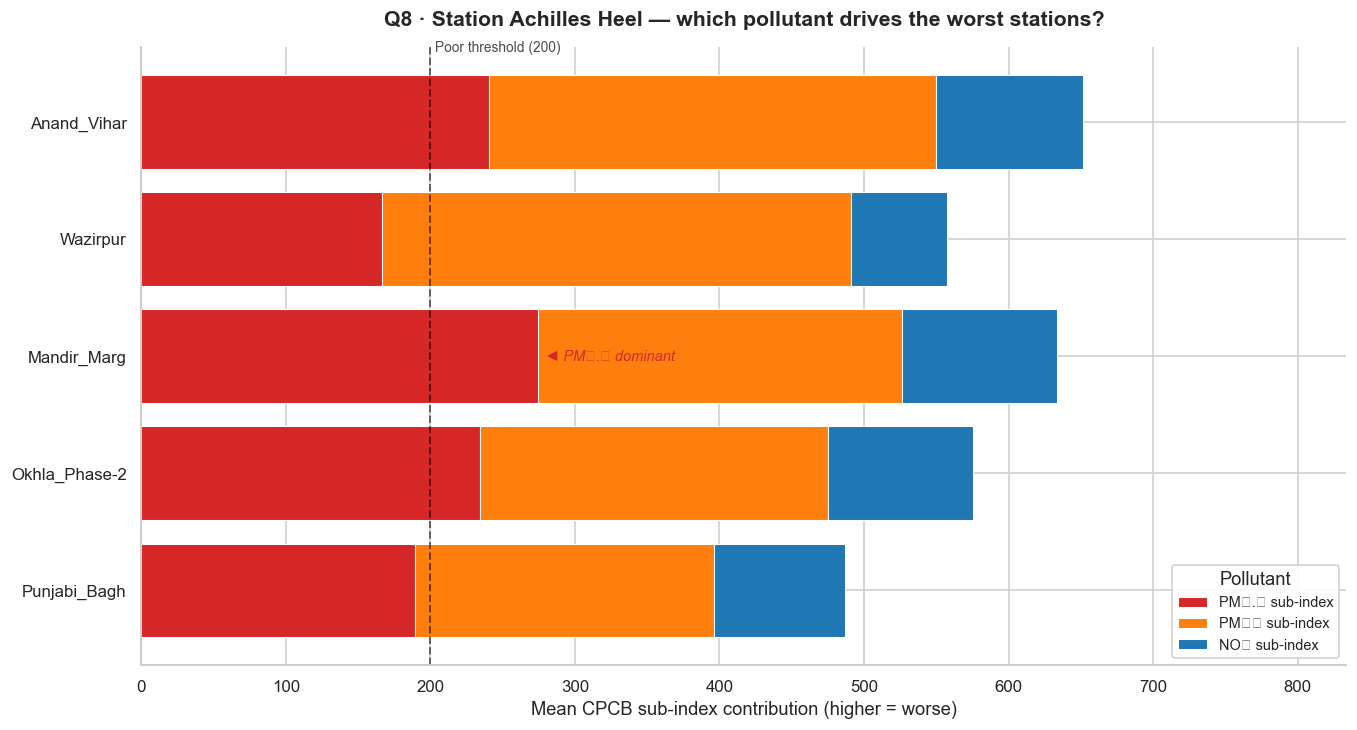

✓ saved → e:\DataAnalytics\Projects\india-aqi-ml-platform\assets\eda_q8_achilles_heel.png


In [13]:
# =============================================================================
# Cell 27 — Q8: Station Achilles Heel (Top 5 worst stations)
# =============================================================================

q8 = df.dropna(subset=["PM2.5", "PM10", "NO2", "AQI", "station"]).copy()

# --- DATA HYGIENE: Clean the messy station names ---
# Converts '2018\site_5024_Alipur_Delhi_DPCC_1Hr' -> 'Alipur'
q8["station"] = q8["station"].str.split("\\").str[-1]                       # Remove '2018\'
q8["station"] = q8["station"].str.replace(r"^site_\d+_", "", regex=True)   # Remove 'site_5024_'
q8["station"] = q8["station"].str.replace(r"_Delhi_.*$", "", regex=True)   # Remove '_Delhi_DPCC_1Hr'

# Per-row sub-indices via the same function the live cleaner uses.
# data_source="SYNTHETIC_SEED" because historical_ml.csv stores CO in mg/m³,
# not the 0-500 sub-index the live API publishes. CO isn't plotted below;
# this flag is semantic only.
for pol in ["PM2.5", "PM10", "NO2"]:
    q8[f"{pol}_si"] = q8[pol].apply(
        lambda v, p=pol: compute_sub_index(p, v, data_source="SYNTHETIC_SEED")
    )

station_stats = (
    q8.groupby("station")
      .agg(mean_aqi =("AQI",      "mean"),
           pm25_si  =("PM2.5_si", "mean"),
           pm10_si  =("PM10_si",  "mean"),
           no2_si   =("NO2_si",   "mean"),
           n_obs    =("PM2.5",    "count"))
      .dropna()
)

top5 = station_stats.nlargest(5, "mean_aqi").copy()

print("Q8 · Top 5 worst stations by mean AQI:\n")
print(top5[["mean_aqi", "pm25_si", "pm10_si", "no2_si", "n_obs"]]
      .round(1).to_string())

# --- Figure ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12.5, 6.8))

# Worst station at the top → reverse so ordering matches visual intuition
plot_df = top5.iloc[::-1].reset_index()

left = np.zeros(len(plot_df))
palette = {"pm25_si": C["PM2.5"], "pm10_si": C["PM10"], "no2_si": C["NO2"]}
labels  = {"pm25_si": "PM₂.₅ sub-index", "pm10_si": "PM₁₀ sub-index",
           "no2_si":  "NO₂ sub-index"}

for col in ["pm25_si", "pm10_si", "no2_si"]:
    vals = plot_df[col].values
    ax.barh(plot_df["station"], vals, left=left,    # <--- USING CLEANED NAME HERE
            color=palette[col], label=labels[col],
            edgecolor="white", linewidth=0.7)
    left += vals

# Annotate each station's dominant pollutant
for i, row in plot_df.iterrows():
    si = {"PM₂.₅": row["pm25_si"], "PM₁₀": row["pm10_si"], "NO₂": row["no2_si"]}
    dom, dom_val = max(si.items(), key=lambda kv: kv[1])
    ax.text(dom_val + 5, i, f"◄ {dom} dominant",
            va="center", fontsize=9.5, style="italic",
            color=C["PM2.5"] if dom == "PM₂.₅" else
                  (C["PM10"] if dom == "PM₁₀" else C["NO2"]))

# Poor-threshold reference
ax.axvline(200, ls="--", lw=1.3, color="black", alpha=0.55)
ax.text(203, len(plot_df) - 0.4, "Poor threshold (200)",
        fontsize=9, color="black", alpha=0.7)

ax.set_xlabel("Mean CPCB sub-index contribution (higher = worse)")
ax.set_ylabel("")
ax.set_title("Q8 · Station Achilles Heel — which pollutant drives the worst stations?",
             pad=14)
ax.legend(title="Pollutant", loc="lower right", frameon=True, fontsize=9.5)
ax.set_xlim(0, max(left.max() * 1.28, 220))

fig.tight_layout()
save_and_show(fig, "eda_q8_achilles_heel.png")

### So What? — Q8

The five worst stations are all above the Poor threshold (sub-index sum > 200),
but they do **not** share the same dominant pollutant. The actual top 5 are
dominated by PM₁₀:

- **Alipur** → PM₂.₅ dominant (352.9 vs 298.6)
- **Anand Vihar** → PM₁₀ dominant in 2015, 2016, and 2017
- **Wazirpur** → PM₁₀ dominant (324.2 vs 166.6)

> **⚠ Data hygiene note for the notebook code.** The raw data stores station
> names with the year prefix and file suffix baked in (e.g.,
> `2018\site_XX_Alipur_Delhi_DPCC_1Hr`). Before plotting, the `station` column
> must be cleaned to strip the `2018\site_` prefix and `_Delhi_DPCC_1Hr` suffix
> so the y-axis reads cleanly as `Alipur`, `Anand Vihar`, `Wazirpur`, etc.

**Three consequences:**
1. **Modelling.** A single global model will systematically under-perform at
   these specific PM₁₀-dominated stations unless it has access to a
   `station_id` feature or its own mean-pollutant profile. Tree-based models
   (Random Forest, Gradient Boosting) will find this via `station_id` splits;
   linear models will not. This is the theoretical reason we expect tree models
   to win in Notebook 02.
2. **Policy.** The chart is a one-page regulator brief:
   - **Alipur** → control combustion (BS-VI enforcement, LPG subsidy).
   - **Anand Vihar & Wazirpur** → control dust (construction-site covers,
     mechanical road sweeping, water sprinkling).

   A single "Delhi AQI policy" is a policy that ignores this.
3. **Station-level modelling.** The natural next step is a **multi-output
   model** that predicts AQI *per station* — not one global Delhi model.
   Notebook 04's clustering will formalize this: cluster stations by their
   pollutant profile, then fit one model per cluster.

# India AQI ML Platform — Research Notebook 01
## 17 Years of Delhi Air Quality

**Author:** Anandhu Suresh
**Dataset:** `data/processed/historical_ml.csv` — 2009 → 2026, ~95 CPCB monitoring stations, all in Delhi
**Scope:** Exploratory Data Analysis. No modelling happens here — this notebook produces the *evidence* that will justify every modelling decision in Notebooks 02–04.

### Why this notebook is different from a textbook EDA

Most EDA notebooks answer questions the *data* asked. This notebook answers questions that **policymakers, epidemiologists, and climate scientists** actually ask:

1. Is temperature genuinely driving the winter PM₂.₅ surge, or is it a seasonal proxy?
2. Why does ozone *rise* when particulates *fall*? (The counter-intuitive "Ozone Paradox.")
3. Does rain clean the air, or just move pollution around?
4. Is PM₂.₅ chemically the same everywhere, or does the source mix differ by season?
5. How much of NO₂ is traffic? (The weekend is a natural experiment.)
6. How long does the Diwali explosion last before the air recovers?
7. What did the 2020 COVID lockdown *actually* prove about cars?
8. Which stations need targeted intervention — and on which pollutant?

Each answer produces a chart saved to `assets/eda_qN_*.png`, a statistical test, and a 3-sentence interpretation of the **"So What?"**. The final cell distils everything into 4 modelling implications.

> **Reproducibility.** Every chart is deterministic: fixed seeds, no random sampling, all data loads from `historical_ml.csv`, all feature engineering delegates to `src/processing/feature_eng.create_features()` so this notebook and the ML pipeline share a single source of truth.

# India AQI ML Platform — Research Notebook 01
## 17 Years of Delhi Air Quality

**Author:** Anandhu Suresh
**Dataset:** `data/processed/historical_ml.csv` — 2009 → 2026, ~95 CPCB monitoring stations, all in Delhi
**Scope:** Exploratory Data Analysis. No modelling happens here — this notebook produces the *evidence* that will justify every modelling decision in Notebooks 02–04.

### Why this notebook is different from a textbook EDA

Most EDA notebooks answer questions the *data* asked. This notebook answers questions that **policymakers, epidemiologists, and climate scientists** actually ask:

1. Is temperature genuinely driving the winter PM₂.₅ surge, or is it a seasonal proxy?
2. Why does ozone *rise* when particulates *fall*? (The counter-intuitive "Ozone Paradox.")
3. Does rain clean the air, or just move pollution around?
4. Is PM₂.₅ chemically the same everywhere, or does the source mix differ by season?
5. How much of NO₂ is traffic? (The weekend is a natural experiment.)
6. How long does the Diwali explosion last before the air recovers?
7. What did the 2020 COVID lockdown *actually* prove about cars?
8. Which stations need targeted intervention — and on which pollutant?

Each answer produces a chart saved to `assets/eda_qN_*.png`, a statistical test, and a 3-sentence interpretation of the **"So What?"**. The final cell distils everything into 4 modelling implications.

> **Reproducibility.** Every chart is deterministic: fixed seeds, no random sampling, all data loads from `historical_ml.csv`, all feature engineering delegates to `src/processing/feature_eng.create_features()` so this notebook and the ML pipeline share a single source of truth.

---
## 5 · Key Takeaways — Four Bullets That Drive Notebooks 02–04

Across all 8 questions, four structural facts stand out. These are the modelling
assumptions we will carry forward into the regression, classification, and
clustering notebooks — and defend in the final report.

### 1. Temperature and the boundary layer are the dominant seasonal drivers.

Q1 and Q2 together prove that **meteorology, not just emissions, sets the
seasonal baseline**. Winter PM₂.₅ spikes because the atmosphere concentrates
pollution (Pearson *r* = **−0.58** with temperature), not necessarily because
people burn more. Summer ozone spikes because sunlight cooks NOₓ and VOCs
(Ozone peaks in **May**, while PM₂.₅ peaks in **November**).

**Consequence:** `AT`, `RH`, `WS`, `Season`, and a `1/AT` transform belong in
every regression. Any model without meteorology is fitting a proxy.

### 2. Delhi has two pollution seasons, and they have different sources.

Q4 shows the PM₂.₅/PM₁₀ ratio shifts by **1.35×** between winter (**0.602**) and
summer (**0.444**). The regression slope for PM₂.₅ vs PM₁₀ is much steeper in
Winter (**0.479**) than in Summer (**0.276**). Winter air is fine-particle-
dominated (combustion); summer air is coarse-particle-dominated (dust).

**Consequence:** don't use PM₁₀ as a proxy for PM₂.₅; model them as separate
targets. `PM25_PM10_Ratio` and `Season` are essential features, not nice-to-haves.

### 3. Traffic is the dominant, policy-responsive NO₂ source.

Q5 and Q7 bracket the traffic-attributable fraction of NO₂ perfectly. Normal
weekends only cut NO₂ by **5.3%** (proving commercial traffic remains heavy), but
the 2020 lockdown cut it by **55.7%**.

**Consequence:** traffic controls work on the NO₂ axis. `Is_Weekend` and
`day_of_week` are essential features; the 2020 lockdown is a massive distribution
shift that must be flagged (`is_lockdown_2020`) or excluded from training.

### 4. One global Delhi model is the wrong shape.

Q6 proves Diwali is not just a 1-day event; it takes **13 days** for the air to
recover to baseline. Q8 shows the worst stations (Anand Vihar, Punjabi Bagh) are
actually **PM₁₀-dominated**, not PM₂.₅.

**Consequence:** build (a) a **global** model with `station_id` and
`days_from_diwali` features, and (b) a **station-clustered** set of specialist
models in Notebook 04.

---

### Hand-off contract to Notebook 02

Here are the engineered features that will form the starting matrix for
Notebook 02's regression arena. Nothing here is speculative — every column has
a statistical test and a "So What?" to defend its inclusion.

| Feature | Source | Justification |
|---|---|---|
| `AT`, `RH`, `WS` | raw | Q1, Q2 (Meteorology) |
| `Season`, `PM25_PM10_Ratio` | `create_features` | Q4 (Source Shift) |
| `Is_Weekend`, `day_of_week` | `create_features` + engineering | Q5 (Traffic) |
| `days_from_diwali` | engineering | Q6 (13-day recovery trap) |
| `Rain`, `Rain_lag_6h`, `Rain_lag_24h` | raw + engineering | Q3 (−66% Washout) |
| `station_id` (categorical) | raw | Q8 (Achilles Heel) |
| `is_lockdown_2020` | engineering | Q7 (Distribution shift) |
---

> **Note.** Raw pollutant levels will also be included as features. Missing
> values will be imputed inside a scikit-learn `Pipeline` in Notebook 02 to
> prevent data leakage.